# Fixed Income Risk Workstation
### Final Integration · Five-Module Front-Office RAD Portfolio

**Valuation & DV01 · Daily VaR Walk · P&L Explain · Incident Screening · Policy Evaluation**

> **Business question:** Can a desk user select one reporting date, reconcile position risk and P&L, review operational exceptions, and understand the controls behind the risk report?

| System component | Responsibility |
|:--|:--|
| Python / NumPy / pandas | Source analytics and retrospective scenario testing |
| Five task snapshots | Reproducible and inspectable output contracts |
| This notebook | Cross-task validation, integration and reporting handoff |
| C# / .NET 10 / ClosedXML | Build the interactive, macro-free Excel workstation |
| Excel | One global report-date selector and eight user-facing sheets |

**Scope:** Simulated government-bond rates desk; 2024 reporting dates for the unified selector. The Task 1 book and stress model are explicitly anchored to the **2024-12-31** closing book. Incident labels and corrections from Task 4 are retrospective evidence, not live screening inputs.

**Attribution:** This is an educational extension of [RiskHub's Fixed Income Risk Dashboard Python Lab](https://riskhub.org/python-labs/fixed-income-risk-dashboard). It is not a production control system.

---

## 01 · Environment & Input Contract

The five modules are intentionally kept separate. This notebook consumes their JSON exports rather than reimplementing pricing, risk-walk, P&L or incident simulation logic.

**Required files:** `Excel_Template_Output/task1_snapshot.json` through `task5_snapshot.json`. Execute the export cells in each of the five task notebooks first. Generated snapshots and Excel reports belong in the gitignored output directory.

In [1]:
import json
import os
import math
import shutil
import subprocess
from pathlib import Path
from collections import Counter
from statistics import median

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when the notebook starts at the repository root or a child folder.
if os.environ.get("RAD_RISK_ROOT"):
    PROJECT_ROOT = Path(os.environ["RAD_RISK_ROOT"]).expanduser().resolve()
else:
    here = Path.cwd().resolve()
    PROJECT_ROOT = next(
        (p for p in (here, *here.parents) if (p / "Excel_Template_Output" / "task1_snapshot.json").is_file()),
        here,
    )
OUTPUT_DIR = PROJECT_ROOT / "Excel_Template_Output"
SOURCE_FILES = [OUTPUT_DIR / f"task{i}_snapshot.json" for i in range(1, 6)]
missing = [str(p) for p in SOURCE_FILES if not p.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing exports. Run the JSON export cells in Task 1–5 before Final.ipynb:\n" + "\n".join(missing)
    )
raw = [json.loads(path.read_text(encoding="utf-8")) for path in SOURCE_FILES]
t1, t2, t3, t4, t5 = raw
print("Project root:", PROJECT_ROOT)
print("Source snapshots:")
for file, content in zip(SOURCE_FILES, raw):
    print(f"  {file.name:<24} {file.stat().st_size:>10,} bytes | as-of {content['asOf']}")

Project root: C:\Users\franklinpeng\Desktop\RDA Risk test
Source snapshots:
  task1_snapshot.json         107,811 bytes | as-of 2024-12-31
  task2_snapshot.json         337,968 bytes | as-of 2024-12-31
  task3_snapshot.json         566,634 bytes | as-of 2024-12-31
  task4_snapshot.json         141,268 bytes | as-of 2024-12-31
  task5_snapshot.json       1,051,741 bytes | as-of 2024-12-31


## 02 · Cross-Module Quality Gates

Before publication, the integration checks that the source modules agree on year-end Net DV01, 99% HS VaR and Reported P&L; that daily attribution and P&L reconciliations are complete; and that Task 5 policy selection is consistent with its precommitted acceptance criteria.

**Important boundary:** Task 4 uses the as-received risk system for screening. Task 5 simulates controlled injections against a retrospectively corrected clean baseline. These datasets serve different purposes and should not be treated as interchangeable daily signals.

In [2]:
AS_OF = "2024-12-31"
checks = []

def check(name, condition, detail):
    condition = bool(condition)
    checks.append({"name": name, "status": "PASS" if condition else "FAIL", "detail": str(detail)})
    if not condition:
        raise AssertionError(f"{name}: {detail}")

check("As-of dates", all(d.get("asOf") == AS_OF for d in raw),
      ", ".join(str(d.get("asOf")) for d in raw))
check("Task 1 scenario count", len(t1["scenarios"]) == 500 and len(t1["ladder"]) == 11,
      f"scenarios={len(t1['scenarios'])}, tenors={len(t1['ladder'])}")

r2 = {row["date"]: row for row in t2["daily"]}
r3 = {row["date"]: row for row in t3["daily"]}
r4 = {row["date"]: row for row in t4["daily"]}
r5 = {row["date"]: row for row in t5["cleanDays"]}
report_dates = sorted(date for date in r4 if date.startswith("2024-"))
check("Unified date coverage",
      len(report_dates) == 260 and all(set(report_dates).issubset(d) for d in (r2, r3, r4, r5)),
      f"2024 dates={len(report_dates)}, Task 2/3/4/5 aligned")
check("History coverage",
      len(t2["daily"]) == len(t3["daily"]) == len(t5["cleanDays"]) == 518,
      "Task 2, Task 3, Task 5 each contain 518 reporting dates")

net_dv01 = sum(row["dv01"] for row in t1["ladder"])
net_value = sum(row["value"] for row in t1["positions"])
gross_position_dv01 = sum(abs(row["dv01"]) for row in t1["positions"])

check("Closing Net DV01", abs(net_dv01-r2[AS_OF]["dvEnd"]) < 0.01,
      f"Task 1={net_dv01:,.6f} vs Task 2={r2[AS_OF]['dvEnd']:,.6f} USD/bp")
check("Closing VaR", abs(t1["var99"] - r2[AS_OF]["varEnd"]) < 1.0,
      f"Task 1={t1['var99']:,.3f} vs Task 2={r2[AS_OF]['varEnd']:,.3f} USD")
check("Incident as-received VaR", abs(t1["var99"]-t4["closingVar"]["asReceived"]) < 1.0,
      f"Task 4 as-received={t4['closingVar']['asReceived']:,.3f}")
check("Closing reported P&L", abs(t1["reportedPnl"]-r3[AS_OF]["reportedPnl"]) < 0.01,
      f"Task 1={t1['reportedPnl']:,.2f}, Task 3={r3[AS_OF]['reportedPnl']:,.2f}")

walk_gap = max(
    abs(v["dvEnd"]-v["dvStart"]-v["dvTime"]-v["dvMarket"]-v["dvTrades"])
    for v in r2.values()
)
walk_var_gap = max(
    abs(v["varEnd"]-v["varStart"]-v["varTime"]-v["varMarket"]-v["varWindow"]-v["varTrades"])
    for v in r2.values()
)
check("Daily risk walks", walk_gap < 0.01 and walk_var_gap < 0.01,
      f"max DV01 residual={walk_gap:.3g}; max VaR residual={walk_var_gap:.3g}")

pnl_gap = max(abs(v["reportedPnl"]-v["predictedPnl"]-v["unexplained"]) for v in r3.values())
market_gap = max(abs(v["marketPnl"]-sum(v["tenorPnl"])) for v in r3.values())
check("P&L explain", pnl_gap < 0.01 and market_gap < 0.01,
      f"max explain residual={pnl_gap:.3g}; max tenor residual={market_gap:.3g}")

screen_gap = max(abs(r3[d]["unexplained"]-r4[d]["unexplained"]) for d in report_dates)
check("Task 3 to Task 4 observed P&L", screen_gap < 0.01,
      f"max U residual={screen_gap:.3g} USD")

check("Task 5 simulation scope", len(t5["trialRecords"])==1200 and len(t5["policies"])==5,
      "1,200 seeded trials; five candidate policies")

# Recalculate coverage and clean-year counts from the underlying trial and clean-day records.
policy_details = []
for p in t5["policies"]:
    name = p["name"]
    trials = [next(x for x in trial["results"] if x["policy"]==name)
              for trial in t5["trialRecords"]]
    caught = sum(x["caught"] for x in trials)
    delay = median([x["delay"] for x in trials if x["caught"]])
    clean23 = sum(day["policyFlags"][name] for day in t5["cleanDays"] if day["year"] == 2023)
    clean24 = sum(day["policyFlags"][name] for day in t5["cleanDays"] if day["year"] == 2024)
    by_kind = {k["kind"]: k["rate"] for k in p["byKind"]}
    passes = caught/1200 >= 0.90 and min(by_kind.values()) >= 0.80 and clean23<=5 and clean24<=5
    assert abs(caught/1200-p["overall"])<1e-9 and delay == p["medianDelay"]
    assert (clean23,clean24,passes)==(p["clean2023"],p["clean2024"],p["passes"])
    policy_details.append((name, clean23+clean24, delay, passes))
eligible = [row for row in policy_details if row[3]]
calculated_winner = min(eligible, key=lambda x:(x[1],x[2]))[0] if eligible else ""
check("Precommitted policy sign-off", calculated_winner == t5["winner"],
      f"winner={calculated_winner}; clean flags tie-break preserved")

qa = pd.DataFrame(checks)
display(qa)
print(f"Integration QA: {len(checks)} / {len(checks)} PASS")

,name,status,detail
0,As-of dates,PASS,"2024-12-31, 2024-12-31, 2024-12-31, 2024-12-31..."
1,Task 1 scenario count,PASS,"scenarios=500, tenors=11"
2,Unified date coverage,PASS,"2024 dates=260, Task 2/3/4/5 aligned"
3,History coverage,PASS,"Task 2, Task 3, Task 5 each contain 518 report..."
4,Closing Net DV01,PASS,"Task 1=47,234.457739 vs Task 2=47,234.457739 U..."
5,Closing VaR,PASS,"Task 1=939,305.680 vs Task 2=939,305.680 USD"
6,Incident as-received VaR,PASS,"Task 4 as-received=939,305.680"
7,Closing reported P&L,PASS,"Task 1=286,426.72, Task 3=286,426.72"
8,Daily risk walks,PASS,max DV01 residual=4.59e-11; max VaR residual=0
9,P&L explain,PASS,max explain residual=0; max tenor residual=4.6...


Integration QA: 13 / 13 PASS


## 03 · Unified Risk Snapshot

The summary distinguishes **report-date-dependent risk** from the **fixed 2024-12-31 position book**. Task 2 provides daily VaR/DV01 across 2024; Task 3 provides daily P&L; Task 4 provides observed screens; Task 5 provides retrospective policy results.

The ultimate Excel Command Center uses one 2024 date selector and formula links to change the Task 2–4 analysis together.

In [3]:
summary = pd.DataFrame([
    ("Closing book date", AS_OF, "Task 1 — static"),
    ("Live bond positions", len(t1["positions"]), "Task 1 — static"),
    ("Net portfolio value (USD)", round(net_value, 2), "Task 1 — static"),
    ("Net DV01 (USD/bp)", round(net_dv01, 2), "Task 1 / Task 2"),
    ("Gross position DV01 (USD/bp)", round(gross_position_dv01, 2), "Task 1 — static"),
    ("1-day 99% VaR (USD)", round(t1["var99"], 2), "Task 1 / Task 2"),
    ("2024 Scaled P&L alerts", t3["defaultScaledCount"], "Task 3 — as-received"),
    ("2024 Stale runs", len(t4["staleRuns"]), "Task 4 — as-received"),
    ("2024 Kink jumps", len(t4["kinkJumps"]), "Task 4 — per vertex"),
    ("Selected offline policy", t5["winner"], "Task 5 — simulation"),
], columns=["Metric", "Value", "Evidence"])
display(summary)

,Metric,Value,Evidence
0,Closing book date,2024-12-31,Task 1 — static
1,Live bond positions,17,Task 1 — static
2,Net portfolio value (USD),324335641.38,Task 1 — static
3,Net DV01 (USD/bp),47234.46,Task 1 / Task 2
4,Gross position DV01 (USD/bp),600193.12,Task 1 — static
5,1-day 99% VaR (USD),939305.68,Task 1 / Task 2
6,2024 Scaled P&L alerts,34,Task 3 — as-received
7,2024 Stale runs,1,Task 4 — as-received
8,2024 Kink jumps,6,Task 4 — per vertex
9,Selected offline policy,SCALED+FEED+LATE,Task 5 — simulation


## 04 · Risk Shape & Policy Review

These are visual checks for GitHub readers. The production-style Excel view retains the same metrics, with report-date selection handled in Excel formulas.

A **negative** Key-Rate DV01 corresponds to a gain from an *upward* isolated yield shock; all stress P&L is a **first-order approximation**.

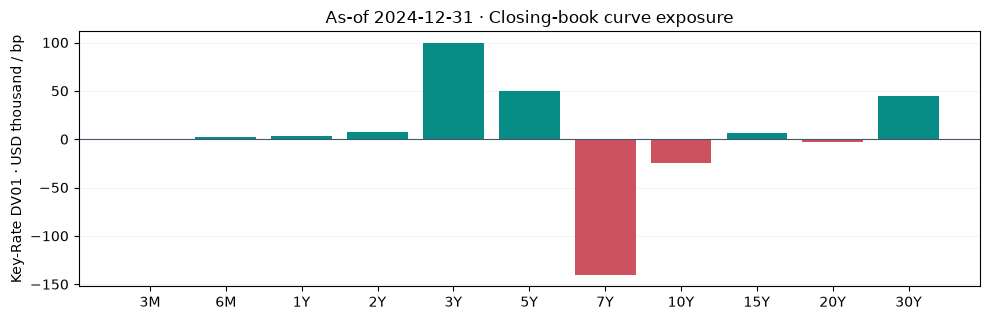

,Policy,Detection,Clean 2023,Clean 2024,Pass
0,PNL_FIXED,83.9%,1,5,False
1,PNL_SCALED,80.8%,1,0,False
2,SCALED+FEED,87.7%,1,0,False
3,SCALED+FEED+LATE,93.8%,1,0,True
4,ALL+PERSIST,94.8%,6,3,False


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.3))
tenors = [v["tenor"] for v in t1["ladder"]]
values = np.array([v["dv01"] for v in t1["ladder"]]) / 1000
ax.bar(tenors, values, color=["#078C86" if x>=0 else "#CD5260" for x in values])
ax.axhline(0,color="#475569",linewidth=0.8)
ax.set_ylabel("Key-Rate DV01 · USD thousand / bp")
ax.set_title("As-of 2024-12-31 · Closing-book curve exposure")
ax.grid(axis="y",alpha=.15)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

pol = pd.DataFrame([{"Policy":p["name"], "Detection":p["overall"],
                     "Clean 2023":p["clean2023"], "Clean 2024":p["clean2024"],
                     "Pass":p["passes"]} for p in t5["policies"]])
display(pol.style.format({"Detection":"{:.1%}"}))

## 05 · Build a Validated Workstation Contract

The JSON produced here is a **presentation contract**, not another risk engine. It includes all 260 aligned 2024 report dates and the year-end book, with retrospective case evidence isolated from the daily screen data.

No live incidents, approvals, official limits or real-time prices are inferred from the training dataset. Data required for Task 1–5 independent drilldowns remain in their original JSON snapshots.

In [5]:
# Merge historical 2024 observations without inventing a date series.
date_rows = []
for date in report_dates:
    a, b, c = r2[date], r3[date], r4[date]
    date_rows.append({
        "date": date,
        "dvStart":a["dvStart"], "dvTime":a["dvTime"],
        "dvMarket":a["dvMarket"], "dvTrades":a["dvTrades"], "dvEnd":a["dvEnd"],
        "varStart":a["varStart"], "varTime":a["varTime"],
        "varMarket":a["varMarket"], "varWindow":a["varWindow"],
        "varTrades":a["varTrades"], "varEnd":a["varEnd"],
        "reportedPnl":b["reportedPnl"], "carry":b["carry"],
        "marketPnl":b["marketPnl"], "predictedPnl":b["predictedPnl"],
        "unexplained":b["unexplained"], "noiseSd":b["noiseSd"],
        "zScore":b["zScore"], "tenorPnl":b["tenorPnl"],
        "screens":{key: bool(c["flags"][key])
                   for key in ("PNL_FIXED","PNL_SCALED","STALE","KINK","LATE")},
        "staleEvidence":c["staleEvidence"],
        "kinkEvidence":c["kinkEvidence"],
        "lateTickets":c["lateTickets"],
    })

contract = {
    "schemaVersion": 1,
    "asOf": AS_OF,
    "reportDateScope": "2024-only: 260 aligned report mornings",
    "risk": {
        "var99": t1["var99"], "netDv01": net_dv01,
        "grossPositionDv01": gross_position_dv01, "netValue": net_value,
        "positions":t1["positions"], "ladder":t1["ladder"],
        "scenarios":t1["scenarios"],
        "curveImage":t1["curveImage"], "lossImage":t1["lossImage"],
    },
    "dateRows":date_rows,
    "pnlCalibration": {
        "fitNoiseBp":t3["fitNoiseBp"],
        "defaultSigma":t3["defaultSigma"],
        "fixedCount2024":t3["defaultFixedCount"],
        "scaledCount2024":t3["defaultScaledCount"],
    },
    "forensic": {
        "screenMethod":"as-received 2024; not retrospectively corrected",
        "staleRuns":t4["staleRuns"],
        "kinkJumps":t4["kinkJumps"],
        "lateBookings":t4["lateBookings"],
        "casesEvaluationOnly":t4["incidentsEvaluationOnly"],
        "closingVar":t4["closingVar"],
    },
    "policy": {
        "winner":t5["winner"], "policies":t5["policies"],
        "simulationSeed":t5["simulationSeed"],
        "trialCount":len(t5["trialRecords"]),
        "incidentsPerKind":t5["incidentsPerKind"],
        "kinds":t5["kindNames"],
        "acceptanceRule":t5["precommittedRule"],
    },
    "validation":{"checks":checks, "passCount":len(checks)}
}
assert all(isinstance(r['tenorPnl'],list) and len(r['tenorPnl'])==11 for r in date_rows)
assert len(contract["dateRows"]) == 260
output = OUTPUT_DIR / "workstation_snapshot.json"
output.write_text(json.dumps(contract, ensure_ascii=False, allow_nan=False), encoding="utf-8")
print(f"Workstation contract: {output}")
print(f"Aligned report dates: {len(date_rows)}; QA checks: {len(checks)}")
print(f"Size: {output.stat().st_size:,} bytes")

Workstation contract: C:\Users\franklinpeng\Desktop\RDA Risk test\Excel_Template_Output\workstation_snapshot.json
Aligned report dates: 260; QA checks: 13
Size: 359,046 bytes


## 06 · Generate the Interactive Excel Application

The workbook is generated by `Excel_Template_Design/DeskRiskWorkstation_Final.cs`. Only C# owns presentation layout; the Python outputs remain the risk calculation source of truth.

The workbook offers **eight user-facing sheets**. The global date selector is on `01 Command Center!C6`; `02 Portfolio Risk` and `07 Stress Lab` are clearly labeled as fixed closing-book snapshots. All other modules use the chosen 2024 report date or label their results as offline summaries.

In [6]:
CS_FILE = PROJECT_ROOT / "Excel_Template_Design" / "DeskRiskWorkstation_Final.cs"
if not CS_FILE.is_file():
    print(f"Excel publish skipped; C# source is not installed: {CS_FILE}")
elif shutil.which("dotnet") is None:
    print("Excel publish skipped: .NET 10 SDK is not available in this environment.")
else:
    proc = subprocess.run(
        ["dotnet", "run", "--file", str(CS_FILE)],
        cwd=PROJECT_ROOT,
        capture_output=True, text=True, encoding="utf-8", errors="replace"
    )
    print(proc.stdout)
    if proc.stderr.strip():print(proc.stderr)
    if proc.returncode != 0:
        raise RuntimeError(f"C# workbook generation failed (exit {proc.returncode})")

SUCCESS: C:\Users\franklinpeng\Desktop\RDA Risk test\Excel_Template_Output\RatesDesk_RiskWorkstation_FINAL_2024-12-31.xlsx
Global 2024 reporting days: 260; positions: 17; scenarios: 500
Closing VaR: USD 939,306; Net DV01: 47,234 USD/bp
Offline policy: SCALED+FEED+LATE; Python QA checks: 13 PASS



## 07 · Output & Delivery QA

This last check verifies the file name and the workbook ZIP structure if the Excel export was run. It does **not** claim to verify Excel's calculation engine or C# compilation on platforms where .NET is unavailable. After generating locally, open the workbook in desktop Excel, select two different dates and check formula updates on the Command Center and related sheets.

In [7]:
import zipfile
import xml.etree.ElementTree as ET

workbook = OUTPUT_DIR / f"RatesDesk_RiskWorkstation_FINAL_{AS_OF}.xlsx"
if workbook.exists():
    with zipfile.ZipFile(workbook) as zf:
        assert zf.testzip() is None, "Corrupted ZIP/Excel member"
        root = ET.fromstring(zf.read("xl/workbook.xml"))
        ns={"m":"http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
        sheets=[el.attrib["name"] for el in root.findall("m:sheets/m:sheet",ns)]
        assert len(sheets) >= 8
    print("Workbook:", workbook.name)
    print("Sheets:", sheets)
    print("Workbook size:", f"{workbook.stat().st_size:,}", "bytes")
else:
    print("Excel workbook not generated in this environment. Contract and Python QA are complete.")

Workbook: RatesDesk_RiskWorkstation_FINAL_2024-12-31.xlsx
Sheets: ['01 Command Center', '02 Portfolio Risk', '03 Risk Attribution', '04 PnL Explain', '05 Incident Monitor', '06 Policy Governance', '07 Stress Lab', '08 Methodology', '_DATA', '_TREND']
Workbook size: 219,212 bytes


## 08 · Operating Model, Limits & GitHub Handoff

**Operating workflow:** Analysts refresh the five independent tasks when needed, run `Final.ipynb` to validate and merge outputs, then generate a macro-free desktop Excel workbook. The report is **end-of-day**, not a live market data service.

**Controls:** Report-date coverage, exact attribution arithmetic, 2024 observed-screen consistency, five-policy acceptance and Task 1/2/4 closing VaR agreement. These are necessary *data and numerical checks*, not a full market-risk model-validation framework.

**Known limitations:** Linear Key-Rate DV01, limited bond universe, simulated trade/market faults, no position history in the integrated `02 Portfolio Risk` worksheet, no official approved risk limits, no live refresh or trade booking, and no external approval/signature workflow. Model selection in Task 5 is an offline synthetic evaluation, not a production sign-off.

**Repository:** Keep this Notebook at the repository root, the C# source under `Excel_Template_Design/`, and all generated snapshots and `.xlsx` files under the gitignored `Excel_Template_Output/`. The root `README.md` contains the module map and run order.

**Portfolio purpose:** Demonstrate practical front-office RAD integration: risk analytics, clear source-of-truth boundaries, spreadsheet UI, repeatable reconciliation, and explicit separation of observed risk from retrospective evidence.